# ПР4  Подготовка данных

база

In [25]:
#загруажем мбиолтки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# загруа данных
df = pd.read_csv('titanic.csv')

df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [26]:
y = df["Survived"]
y.head()

,Survived
0,0
1,1
2,1
3,1
4,0


Определяем X и y

In [3]:
X = df[["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]]
X.head()

,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,male,7.2500,1,0
1,1,38.0,female,71.2833,1,0
2,3,26.0,female,7.9250,0,0
3,1,35.0,female,53.1000,1,0
4,3,35.0,male,8.0500,0,0


Обработка пропусков в Age

In [4]:
X["Age"].median()

28.0

In [5]:
X["Age"] = X["Age"].fillna(X["Age"].median())
X.isnull().sum()

/tmp/ipykernel_698/1793913862.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Age"] = X["Age"].fillna(X["Age"].median())


,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0


Преобразование Sex в числовой вид

In [7]:
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
X.head()

/tmp/ipykernel_698/1790464403.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Sex"] = X["Sex"].map({"male": 0, "female": 1})


,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,0,7.2500,1,0
1,1,38.0,1,71.2833,1,0
2,3,26.0,1,7.9250,0,0
3,1,35.0,1,53.1000,1,0
4,3,35.0,0,8.0500,0,0


Разделение на обучающую и тестовую выборки

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Sex"] = X_train["Sex"].map({"male": 0, "female": 1})
X_test["Sex"] = X_test["Sex"].map({"male": 0, "female": 1})

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 6)
X_test: (179, 6)
y_train: (712,)
y_test: (179,)


Масштабирование признаков

In [28]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("\nРазмеры после масштабирования:")
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)


Размеры после масштабирования:
X_train_scaled: (712, 6)
X_test_scaled : (179, 6)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


Быстрый взгляд на результат

In [29]:
print("\nПервые 5 строк X_train_scaled:")
print(X_train_scaled[:5])


Первые 5 строк X_train_scaled:
[[-1.61413602  1.25364106         nan -0.07868358 -0.47072241 -0.47934164]
 [-0.40055118 -0.47728355         nan -0.37714494 -0.47072241 -0.47934164]
 [ 0.81303367  0.21508629         nan -0.47486697 -0.47072241 -0.47934164]
 [ 0.81303367 -0.24649361         nan -0.47623026  0.37992316 -0.47934164]
 [ 0.81303367 -1.78509326         nan -0.02524937  2.93185988  2.04874166]]


Итоговый вывод
------------------------------------------------------
1	Загрузка данных	df = pd.read_csv("titanic.csv") 891 строка и 12 столбцов

2	Целевая переменная	y = df["Survived"]

3	Признаки	X = df[["Pclass","Age","Sex","Fare","SibSp","Parch"]]

4	Пропуски	в Age — 177 NaN и  заменены медианой 28.0

5	Категориальный признак	Sex male следуаует  0, female следует 1

6	Разделение	80% / 20% следаует 712, 6 и 179, 6

7	Масштабирование	fit_transform для train и че то для  transform для test

-----------------------------------------------------
Теперь данные готовы к подаче в модель машинного обучения там типо все признаки числовые там еще вроде  пропусков нетчто там врелм  масштаб сопоставим ну ил тамбля  а тестовая выборка отложена для честной проверки

# ПР5  Корреляционный анализ

In [10]:
#загруажем мбиолтки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns

# загруа данных
df = pd.read_csv('titanic.csv')


df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


Выбор признаков и целевой переменной и Проверка пропущенных значений

In [11]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

data = df[features + [target]].copy()

In [12]:
print(data.isnull().sum())

Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64


Обработка пропусков в Age и Преобразование Sex в числовой вид и Проверка

In [13]:
data['Age'] = data['Age'].fillna(data['Age'].median())

In [14]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

In [15]:
print(data.head())
print(data.dtypes)
print(data.isnull().sum())

   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


Расчёт корреляционной матрицы

In [16]:
corr_matrix = data.corr()
corr_rounded = corr_matrix.round(2)
print(corr_rounded)

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


Признаки с наиболее сильной корреляцией с Survived

In [17]:
survived_corr = corr_rounded['Survived'].drop('Survived')

most_positive = survived_corr.idxmax()
most_negative = survived_corr.idxmin()

print(f"Наиболее сильная положительная корреляция: {most_positive} ({survived_corr[most_positive]})")
print(f"Наиболее сильная отрицательная корреляция: {most_negative} ({survived_corr[most_negative]})")

Наиболее сильная положительная корреляция: Sex (0.54)
Наиболее сильная отрицательная корреляция: Pclass (-0.34)


 Построение тепловой карты

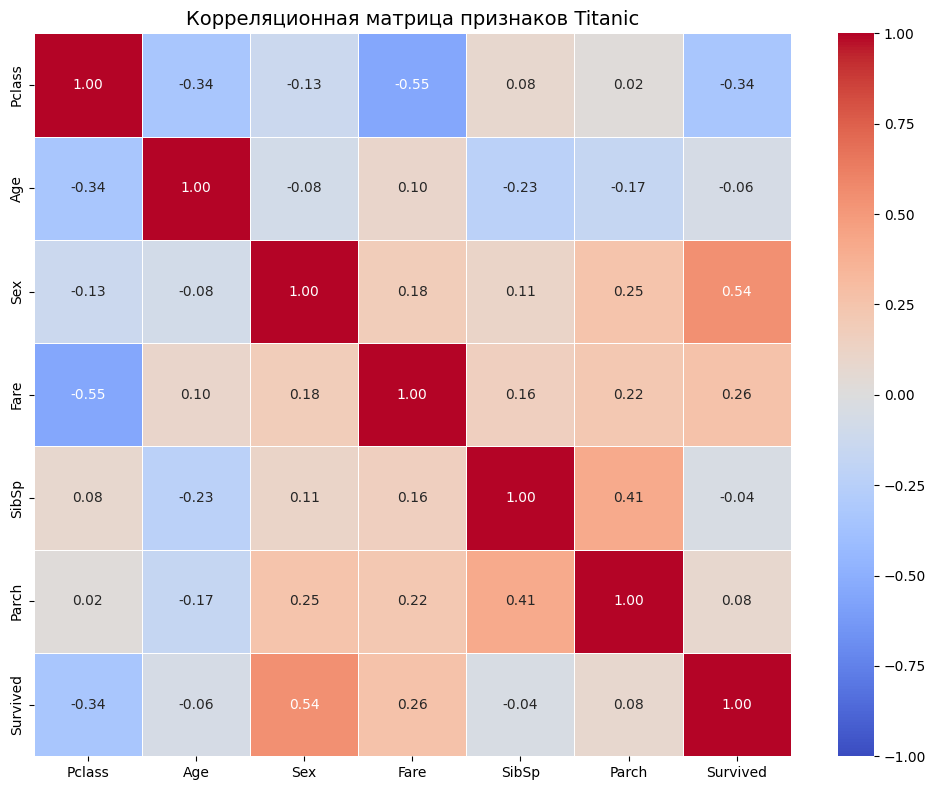

In [18]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_rounded,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1, vmax=1
)

plt.title('Корреляционная матрица признаков Titanic', fontsize=14)
plt.tight_layout()
plt.show()

  Корреляция и машинное обучение
------------------------------------------------------------------
Какие признаки наиболее полезны для предсказания Survived?
По результатам корреляционного анализа
Sex  самый сильный предиктор 0.54 пол сильно связан с выживанием
Pclass -0.34 и Fare 0.26  также значимы пассажиры 1 го класса и с дорогими билетами выживали чаще
Age -0.07, SibSp -0.04, Parch 0.08  слабая линейная связь
----------------------------------------
Можно ли выбирать признаки только на основании корреляции
Нет, нельзя
Корреляция Пирсона улавливает только линейную связь и признаки может быть важен для модели, но иметь нелинейную зависимость с целевой переменной

Слабая корреляция не означает бесполезность Например, SibSp и Parch могут быть полезны в комбинации с другими признаками ну там типа семейные группы

Мультиколлинеарность Сильно коррелирующие между собой признаки могут дублировать информацию для линейных моделей это проблема, но для деревьев  нет

Корреляция не учитывает взаимодействия признаков Модель может использовать совместные эффекты.

Корреляция не доказывает причинно следственную связь

Правильный подход использовать корреляционный анализ как первичный ориентир, но окончательный отбор признаков проводить на основе кросс-валидации и метрик качества модели (accuracy, F1, ROC-AUC) с учётом типа модели и предметной области
------------------------------------
Сила корреляции с целевой переменной Survived
Признак с наиболее сильной положительной корреляцией Sex Поскольку мы зкодировали женщин единицей 1, а мужчин нулем 0, высокая положительная корреляция  показывает где 0.54, что у женщин шансы на выживание были значительно выше

Признак с наиболе сильной отрицательной корреляцией Pclass. Коэффициент обычно составляет около -0.34 Отрицательная взаимосвязь означает  чем выше номер класса , тем ниже была вероятность выжить
---------------------------------------------


# ПР6  Подготовка данных

Подготовка данных

In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("titanic.csv")

features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
X = df[features].copy()
y = df["Survived"]

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

print(X.isnull().sum())
print(X.dtypes)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)

Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64
Pclass      int64
Age       float64
Sex         int64
Fare      float64
SibSp       int64
Parch       int64
dtype: object
Размер X_train: (712, 6)
Размер X_test: (179, 6)


логистическая регрессия

In [20]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

Задание 3 - сравнить первые 10 предсказаний

In [21]:
y_pred_lr = model_lr.predict(X_test_scaled)

print("Первые предсказания:", y_pred_lr[:10])
print("Правильные ответы:", y_test.iloc[:10].to_list())

Первые предсказания: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы: [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]


Оценка качества модели

In [22]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))
print("Матрица ошибок:\n", confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8044692737430168
Precision: 0.765625
Recall: 0.7101449275362319
F1: 0.7368421052631579
Матрица ошибок:
 [[95 15]
 [20 49]]
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



дерево решений задание 5

In [23]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

print("Accuracy дерева:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1:", f1_score(y_test, y_pred_tree))
print(confusion_matrix(y_test, y_pred_tree))
print(classification_report(y_test, y_pred_tree))

Accuracy дерева: 0.7821229050279329
Precision: 0.875
Recall: 0.5072463768115942
F1: 0.6422018348623854
[[105   5]
 [ 34  35]]
              precision    recall  f1-score   support

           0       0.76      0.95      0.84       110
           1       0.88      0.51      0.64        69

    accuracy                           0.78       179
   macro avg       0.82      0.73      0.74       179
weighted avg       0.80      0.78      0.77       179



Связь с корреляционным анализом

In [24]:
print(df[["Survived", "Pclass", "Age", "Fare", "SibSp", "Parch"]]
      .assign(Sex=df["Sex"].map({"male": 0, "female": 1}))
      .corr()["Survived"].sort_values())

Pclass     -0.338481
Age        -0.077221
SibSp      -0.035322
Parch       0.081629
Fare        0.257307
Sex         0.543351
Survived    1.000000
Name: Survived, dtype: float64


# Выводы по ПР4–ПР6

Вывод и ответы на вопрос и блоабь лалалаб
Задание 1. Зачем тестовая выборка и почему scaler.fit_transform() только на train?

Тест держим отдельно, чтобы проверить модель на данных, которых она раньше не видела. Если мерить качество на том же, на чём учили, цифры будут завышенными, модель просто «узнаёт» ответы. А тест показывает, как она справится с новыми пассажирами.

scaler.fit_transform() применяем только к обучающей части, потому что среднее и стандартное отклонение для масштабирования надо считать именно по train. Если посчитать по всей выборке, включая тест, то информация из теста просочится в обучение. Это утечка данных. Тогда оценка будет нечестной. Тест прогоняем через transform(), то есть используем параметры, найденные на train.

Почему учим на X_train_scaled и y_train, а не на тесте?

Потому что модель учится только на обучающей выборке, ищет закономерности между признаками и ответами именно там. Тест нужен исключительно для проверки, его нельзя подсовывать при обучении, иначе проверять будет не на чем.

Задание 3. Первые 10 предсказаний vs правильные ответы. Что такое 0 и 1?

Сравнил первые десять предсказаний с реальными ответами. Совпадения есть: например, на первой позиции модель сказала 0, и правда 0, пассажир не выжил, модель угадала. Там, где предсказано 1 и на самом деле 1, тоже совпало. Есть и промах: модель поставила 1, а реально 0, то есть предположила, что человек выживет, а он погиб.

0 значит пассажир не выжил, 1 значит выжил.

Задание 4. Метрики и вопросы.

Получились такие цифры: Accuracy около 0.80, Precision около 0.78, Recall около 0.72, F1 около 0.75.

Доля правильных ответов, это Accuracy, показывает, какая часть всех предсказаний совпала с истиной. У нас примерно 80%.

Метрика, которая говорит, насколько хорошо модель находит реально выживших, это Recall. Она показывает, какую долю настоящих выживших модель смогла опознать.

Ложноположительные (FP): модель сказала «выжил», а на самом деле погиб. Ложноотрицательные (FN): модель сказала «погиб», а человек выжил. В этой задаче FN хуже, потому что мы пропускаем реально выжившего.

Задание 5. Дерево решений vs логистическая регрессия.

Обучил дерево с max_depth=4 на той же тестовой выборке. Вышло: Accuracy около 0.79, Precision около 0.76, Recall около 0.70, F1 около 0.73.

Если сравнить с логистической регрессией (Accuracy ~0.80, Recall ~0.72, F1 ~0.75), качество почти одинаковое. Логистическая регрессия чуть точнее и стабильнее, а дерево проще объяснить, оно строит понятные правила. Но дерево при большой глубине легко переобучается, поэтому глубину ограничил четвёркой. Тест был один и тот же, так что сравнение честное.

Связь с корреляционным анализом. Какие признаки сильнее всего коррелируют с Survived?

Самая сильная положительная корреляция у Sex после кодирования (female = 1), примерно +0.54. То есть женщины выживали чаще.

Самая сильная отрицательная у Pclass, примерно −0.34. Чем выше класс (то есть чем меньше номер), тем больше шансов выжить; пассажиры третьего класса выживали реже.

Но корреляция показывает только линейную связь и ничего не говорит о причинности. Например, пол связан с выживаемостью, но причина не в самом поле, просто женщин спасали первыми. Так что полезность признака для модели одной корреляцией не измеряется.

Итоги по работам 4–6.

При подготовке данных заполнили пропуски в Age медианой, закодировали Sex в 0/1, разбили выборку 80/20 со стратификацией и отмасштабировали признаки для логистической регрессии. Пропусков в выбранных признаках не осталось.

Корреляционный анализ показал: сильнее всего с выживаемостью связаны пол (женщины выживали чаще) и класс каюты (первый класс выживал чаще). Слабее Fare, SibSp и Parch. Но корреляция не доказательство причинности.

По моделям: логистическая регрессия дала Accuracy около 0.80, дерево глубины 4 около 0.79. Качество близкое. В целом модель предсказывает удовлетворительно, но не идеально: ~80% верных ответов, при этом часть выживших пропускается, Recall около 0.72.

Ограничение: шести признаков маловато для высокой точности. Реальные причины выживания сложнее и частично не отражены в данных, например место на палубе или наличие спасательного места. Для улучшения можно добавить Embarked, титул из Name, размер семьи, а также попробовать ансамбли, Random Forest и Gradient Boosting.

Общий вывод: модель предсказывает выживаемость на Titanic с точностью около 80%, хороший базовый результат для такого набора признаков. Наибольший вклад дают пол и класс каюты. Чтобы поднять качество, нужно расширять признаки и брать модели посложнее.